In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime

url = "https://raw.githubusercontent.com/pujarisurakshashankar/car-market-trend-analysis/main/data/CarDekho_Dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
# Display dataset information
print("Columns:", df.columns.tolist())
print("Shape:", df.shape)

df.info()

display(df.describe())

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Create car age
current_year = datetime.now().year

df["Car_Age"] = current_year - df["Year"]

# Remove rows with missing important values
df = df.dropna(subset=[
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Car_Age"
])

# Remove invalid values
df = df[
    (df["Selling_Price"] > 0) &
    (df["Present_Price"] > 0) &
    (df["Kms_Driven"] >= 0) &
    (df["Car_Age"] >= 0)
]

print("Cleaned data:", df.shape)

display(df.head())

Columns: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
Shape: (301, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64
Duplicate rows: 2
Cleaned data: (299, 10)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


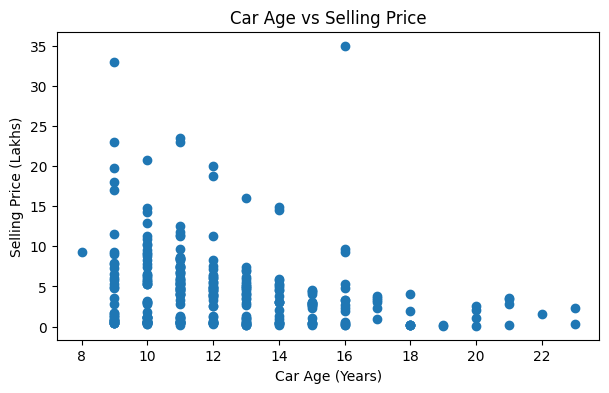

In [3]:
plt.figure(figsize=(7, 4))

plt.scatter(
    df["Car_Age"],
    df["Selling_Price"]
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs)")
plt.title("Car Age vs Selling Price")

plt.show()

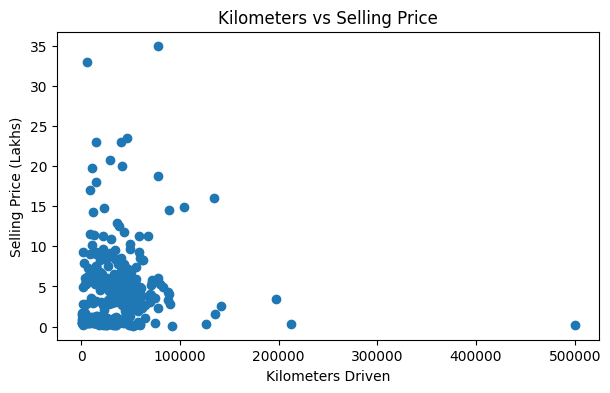

In [4]:
plt.figure(figsize=(7, 4))

plt.scatter(
    df["Kms_Driven"],
    df["Selling_Price"]
)

plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (Lakhs)")
plt.title("Kilometers vs Selling Price")

plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Input columns
features = [
    "Car_Age",
    "Kms_Driven",
    "Present_Price",
    "Fuel_Type",
    "Transmission",
    "Owner",
    "Seller_Type"
]

# X = input
X = df[features]

# y = output
y = df["Selling_Price"]

# Numerical columns
numeric_features = [
    "Car_Age",
    "Kms_Driven",
    "Present_Price"
]

# Categorical columns
categorical_features = [
    "Fuel_Type",
    "Transmission",
    "Owner",
    "Seller_Type"
]

# Handle missing numerical values
numeric_process = SimpleImputer(strategy="median")

# Handle categorical values
category_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Prepare data
preprocessor = ColumnTransformer([
    ("numeric", numeric_process, numeric_features),
    ("category", category_process, categorical_features)
])

# Create model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("linear_regression", LinearRegression())
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [6]:
# Predict test data
y_pred = model.predict(X_test)

# Calculate performance
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2), "Lakhs")
print("RMSE:", round(rmse, 2), "Lakhs")
print("R2 Score:", round(r2, 2))

print("MAE in rupees: ₹", round(mae * 100000))

MAE: 1.45 Lakhs
RMSE: 2.45 Lakhs
R2 Score: 0.77
MAE in rupees: ₹ 144611


In [7]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Dropdown options from dataset
fuel_options = sorted(df["Fuel_Type"].unique())
trans_options = sorted(df["Transmission"].unique())
owner_options = sorted(df["Owner"].unique())
seller_options = sorted(df["Seller_Type"].unique())

# Car age
age_input = widgets.IntSlider(
    value=5,
    min=0,
    max=25,
    description="Car Age:",
    style={"description_width": "initial"}
)

# Kilometers driven
km_input = widgets.IntText(
    value=50000,
    description="Kilometers:",
    style={"description_width": "initial"}
)

# Showroom price in lakhs
price_input = widgets.FloatText(
    value=8.0,
    description="Showroom Price (Lakhs):",
    style={"description_width": "initial"}
)

# Fuel dropdown
fuel_input = widgets.Dropdown(
    options=fuel_options,
    description="Fuel Type:",
    style={"description_width": "initial"}
)

# Transmission dropdown
trans_input = widgets.Dropdown(
    options=trans_options,
    description="Transmission:",
    style={"description_width": "initial"}
)

# Owner dropdown
owner_input = widgets.Dropdown(
    options=owner_options,
    description="Owner Count:",
    style={"description_width": "initial"}
)

# Seller dropdown
seller_input = widgets.Dropdown(
    options=seller_options,
    description="Seller Type:",
    style={"description_width": "initial"}
)

In [14]:
predict_button = widgets.Button(
    description="Predict Car Price",
    button_style="success"
)

result_output = widgets.Output()


def predict_car_price(button):

    with result_output:
        result_output.clear_output()

        # Take user input
        user_data = pd.DataFrame([{
            "Car_Age": age_input.value,
            "Kms_Driven": km_input.value,
            "Present_Price": price_input.value,
            "Fuel_Type": fuel_input.value,
            "Transmission": trans_input.value,
            "Owner": owner_input.value,
            "Seller_Type": seller_input.value
        }])

        # Predict price
        predicted_price = model.predict(user_data)[0]

        # Convert lakhs into rupees
        price_rupees = max(0, predicted_price * 100000)

        print("Car Price Prediction")
        print("-------------------")
        print("Car Age:", age_input.value, "years")
        print("Kilometers Driven:", km_input.value)
        print("Fuel Type:", fuel_input.value)
        print("Transmission:", trans_input.value)
        print("Owner Count:", owner_input.value)

        print("\nPredicted Price: ₹", round(price_rupees, 2))


predict_button.on_click(predict_car_price)

In [15]:
app = widgets.VBox([
    widgets.HTML("<h2>Car Price Prediction</h2>"),

    age_input,
    km_input,
    price_input,
    fuel_input,
    trans_input,
    owner_input,
    seller_input,

    predict_button,
    result_output
])

display(app)